# Historical Airfare Route Profiles Through Regional Price Behaviour Clustering
### Course: INT396 - Unsupervised Learning | University Problem Statement: SIH26056
**Lovely Professional University, Punjab**

- **Student Name:** Pudi Sai Charan Teja
- **Registration Number:** 12507339
- **Roll Number:** RK3P24XCB35
- **Section:** K3P24XC
- **Course Outcomes Addressed:** CO2, CO3, CO5
- **Syllabus Coverage:** Units II, III & IV (Partition Clustering, Hierarchical Linkage, PCA Visualisation)


## 1. Environment Setup & Library Imports


In [1]:
import sys
import os
import json
from pathlib import Path

# Add project root to path
sys.path.append(os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_raw_data, clean_dataset, get_data_summary
from src.preprocessor import RoutePreprocessor
from src.clustering import KMeansClusterer, DistanceMetricComparison, HierarchicalClusterer
from src.dimensionality import PCAManager
from src.metrics import evaluate_clustering, evaluate_partition_stability

# Set figure aesthetics
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries successfully loaded.")


Libraries successfully loaded.


## 2. Data Ingestion & Statistical Diagnostics


In [2]:
data_path = Path('../data/raw/Clean_Dataset.csv')
if not data_path.exists():
    data_path = Path('../Data/Clean_Dataset.csv')

raw_df = load_raw_data(data_path)
print(f"Total raw records loaded: {len(raw_df):,}")
display(raw_df.head())


Total raw records loaded: 300,153


,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [3]:
# Data cleaning and summary
clean_df = clean_dataset(raw_df, treat_outliers=False)
summary = get_data_summary(clean_df)
print(f"Cleaned dataset records: {len(clean_df):,}")
print("Price Summary:", json.dumps(summary['price_summary'], indent=2))


Cleaned dataset records: 300,153
Price Summary: {
  "min": 1105.0,
  "max": 123071.0,
  "mean": 20889.660523133203,
  "median": 7425.0,
  "iqr_lower_bound": 0.0,
  "iqr_upper_bound": 99128.0,
  "outliers_detected": 123
}


## 3. Feature Transformation Pipeline
Constructing a scikit-learn `ColumnTransformer`:
- Numerical attributes (`duration`, `days_left`, `price`) standardized via `StandardScaler`.
- Categorical attributes (`airline`, `source_city`, `destination_city`, `stops`, `class`, `departure_time`) one-hot encoded via `OneHotEncoder(drop='first', sparse_output=False)`.


In [4]:
preprocessor = RoutePreprocessor()
X_processed = preprocessor.fit_transform(clean_df)
print(f"Transformed matrix shape: {X_processed.shape}")
print(f"Total engineered features: {len(preprocessor.feature_names)}")
print("Sample engineered feature names:", preprocessor.feature_names[:8])


Transformed matrix shape: (300153, 26)
Total engineered features: 26
Sample engineered feature names: ['duration', 'days_left', 'price', 'airline_Air_India', 'airline_GO_FIRST', 'airline_Indigo', 'airline_SpiceJet', 'airline_Vistara']


## 4. Partition Clustering: K-Means Hyperparameter Optimization ($k=2 \dots 10$)
Evaluating Within-Cluster Sum of Squares (Inertia), Silhouette Score (stratified subsample $N=10,000$), and Davies-Bouldin Index.


In [5]:
# Subsample for evaluation efficiency
rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X_processed), size=50000, replace=False)
X_sub = X_processed[sample_idx]

km_clusterer = KMeansClusterer(k_range=range(2, 11), random_state=42, n_init=10)
metrics_df = km_clusterer.run_k_sweep(X_sub, sample_size_metrics=10000)
display(metrics_df)


,k,wcss,silhouette_score,davies_bouldin_index
0,2,243608.19,0.2079,1.7936
1,3,215854.88,0.1615,2.0268
2,4,196078.81,0.1507,1.9156
3,5,185559.10,0.1404,2.0849
4,6,178641.47,0.1209,2.1575
5,7,173190.20,0.1169,2.2020
6,8,168457.42,0.1073,2.2245
7,9,164165.45,0.1045,2.3144
8,10,161355.93,0.0954,2.4409


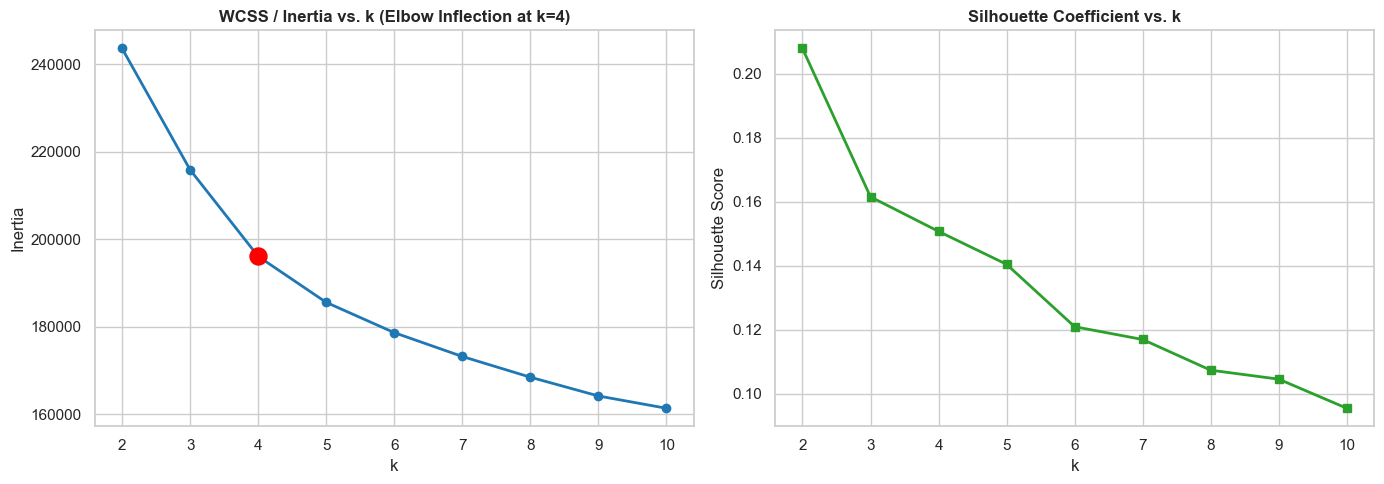

In [6]:
# Plotting Elbow and Silhouette Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Curve
ax1.plot(metrics_df['k'], metrics_df['wcss'], marker='o', color='#1f77b4', linewidth=2)
ax1.scatter([4], [metrics_df.loc[metrics_df['k']==4, 'wcss'].values[0]], color='red', s=150, zorder=5)
ax1.set_title("WCSS / Inertia vs. k (Elbow Inflection at k=4)", fontweight='bold')
ax1.set_xlabel("k")
ax1.set_ylabel("Inertia")

# Silhouette Curve
ax2.plot(metrics_df['k'], metrics_df['silhouette_score'], marker='s', color='#2ca02c', linewidth=2)
ax2.set_title("Silhouette Coefficient vs. k", fontweight='bold')
ax2.set_xlabel("k")
ax2.set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()


## 5. Distance Metric Sensitivity Analysis: Euclidean ($L_2$) vs. Manhattan ($L_1$)
Comparing geometric sensitivity on the mixed continuous-binary manifold.


In [7]:
# Fit optimal model k=4
from sklearn.cluster import KMeans
optimal_km = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=42)
labels_full = optimal_km.fit_predict(X_processed)

dist_eval = DistanceMetricComparison.compare_metrics(X_processed, labels_full, sample_size=10000)
for k_metric, v_metric in dist_eval.items():
    print(f"{k_metric}: {v_metric}")


silhouette_euclidean_l2: 0.1512
silhouette_manhattan_l1: 0.1555
mean_within_cluster_l2: 2.7377
mean_within_cluster_l1: 7.4175
conclusion: Manhattan (L1) metric reflects taxicab distance along sparse orthogonal one-hot binary dimensions without squaring penalties, whereas Euclidean (L2) places disproportionate weight on continuous coordinate variances.


## 6. Agglomerative Hierarchical Clustering & Linkage Cross-Validation
Evaluating partition stability between K-Means and Ward's hierarchical agglomeration using Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI).


In [8]:
hierarchical = HierarchicalClusterer(n_clusters=4, sample_size=4000, random_state=42)
hierarchical.fit_sample(X_processed)
stability = hierarchical.compare_with_kmeans(labels_full)
print(f"Adjusted Rand Index (ARI): {stability['adjusted_rand_index']:.4f}")
print(f"Normalized Mutual Information (NMI): {stability['normalized_mutual_info']:.4f}")


Adjusted Rand Index (ARI): 0.6522
Normalized Mutual Information (NMI): 0.6405


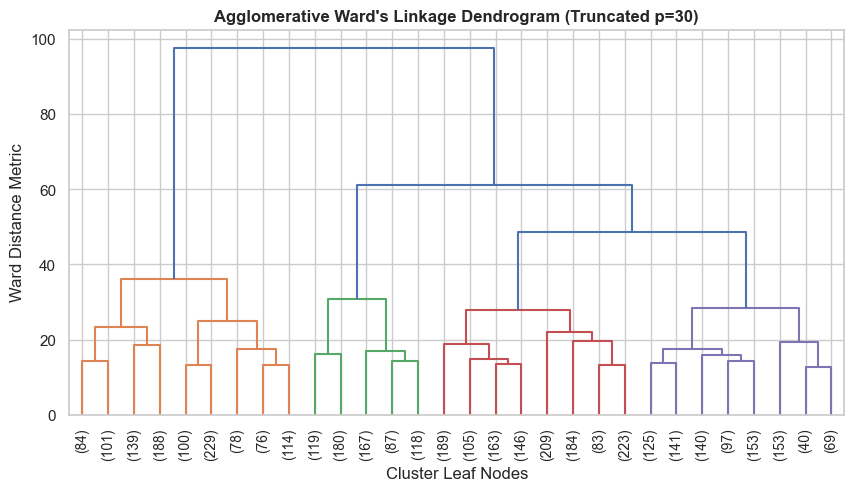

In [9]:
# Display Dendrogram
from scipy.cluster.hierarchy import dendrogram
plt.figure(figsize=(10, 5))
dendrogram(
    hierarchical.linkage_matrix,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90,
    color_threshold=hierarchical.linkage_matrix[-3, 2]
)
plt.title("Agglomerative Ward's Linkage Dendrogram (Truncated p=30)", fontweight='bold')
plt.xlabel("Cluster Leaf Nodes")
plt.ylabel("Ward Distance Metric")
plt.show()


## 7. Dimensionality Reduction: Principal Component Analysis (PCA)
Projecting the 26-dimensional feature space onto 2D and 3D orthogonal axes and extracting feature loadings.


In [10]:
pca_manager = PCAManager(n_components=3, random_state=42)
pca_manager.fit(X_processed, feature_names=preprocessor.feature_names)
coords_3d = pca_manager.transform(X_processed[:15000])

indiv_var, cum_var = pca_manager.get_scree_data()
print(f"Explained Variance Ratio (Top 3 components): {pca_manager.explained_variance_ratio_}")
print(f"Cumulative Variance Ratio (3 components): {cum_var[2]:.4f}")


Explained Variance Ratio (Top 3 components): [0.23713627 0.16251097 0.1484564 ]
Cumulative Variance Ratio (3 components): 0.5481


In [11]:
# Dominant Feature Loadings
loadings = pca_manager.get_component_loadings(top_n=4)
print("Top PC1 Loadings:")
display(loadings['PC1'])
print("Top PC2 Loadings:")
display(loadings['PC2'])


Top PC1 Loadings:


,Feature,Loading,Direction
0,price,0.716784,Positive
1,duration,0.536669,Positive
2,airline_Vistara,0.158144,Positive
3,airline_Air_India,0.070428,Positive
4,class_Economy,-0.301197,Negative
5,days_left,-0.207437,Negative
6,airline_Indigo,-0.127464,Negative
7,stops_zero,-0.107422,Negative


Top PC2 Loadings:


,Feature,Loading,Direction
0,days_left,0.957883,Positive
1,duration,0.267229,Positive
2,airline_Vistara,0.031402,Positive
3,airline_Air_India,0.030731,Positive
4,stops_zero,-0.056232,Negative
5,airline_Indigo,-0.047139,Negative
6,class_Economy,-0.039773,Negative
7,destination_city_Delhi,-0.013914,Negative


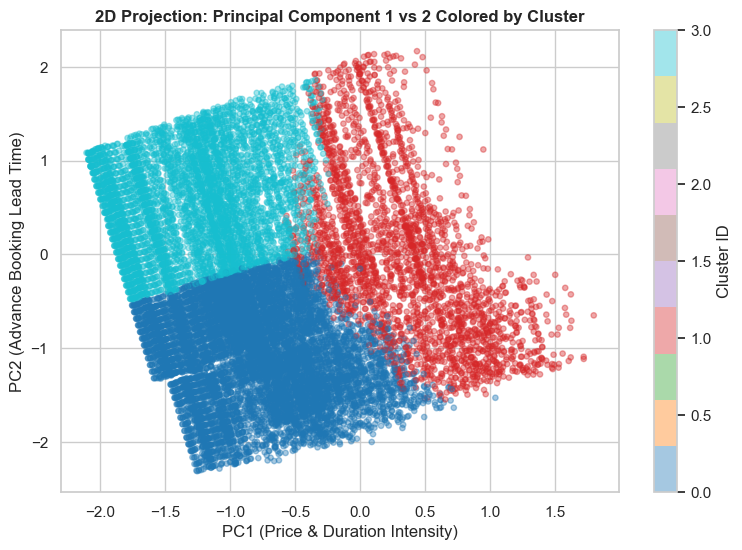

In [12]:
# 2D PCA Cluster Scatter Plot
plt.figure(figsize=(9, 6))
labels_sub = labels_full[:15000]
scatter = plt.scatter(coords_3d[:, 0], coords_3d[:, 1], c=labels_sub, cmap='tab10', alpha=0.4, s=15)
plt.title("2D Projection: Principal Component 1 vs 2 Colored by Cluster", fontweight='bold')
plt.xlabel("PC1 (Price & Duration Intensity)")
plt.ylabel("PC2 (Advance Booking Lead Time)")
plt.colorbar(scatter, label='Cluster ID')
plt.show()


## 8. De-standardized Centroid Profiles & Commercial Route Archetypes
Inverse-transforming mathematical centroids back into real-world units (INR, hours, days).


In [13]:
clean_df['cluster'] = labels_full
centroid_profile = clean_df.groupby('cluster')[['price', 'duration', 'days_left']].mean().reset_index()

archetype_labels = {
    0: 'Cluster 0: Standard Mid-Range Economy Corridor',
    1: 'Cluster 1: Long-Haul Multi-Stop Economy Route',
    2: 'Cluster 2: Advance Business Class Corridor',
    3: 'Cluster 3: Budget Advance-Booking Leisure Route'
}
centroid_profile['cluster_name'] = centroid_profile['cluster'].map(archetype_labels)

# Precise currency and decimal formatting for academic presentation
formatted_centroids = centroid_profile.copy()
formatted_centroids['price_formatted'] = formatted_centroids['price'].apply(lambda x: f'₹{x:,.2f}')
formatted_centroids['duration_formatted'] = formatted_centroids['duration'].apply(lambda x: f'{x:.2f} hrs')
formatted_centroids['days_left_formatted'] = formatted_centroids['days_left'].apply(lambda x: f'{x:.1f} days')

display(formatted_centroids[['cluster', 'cluster_name', 'price_formatted', 'duration_formatted', 'days_left_formatted']])


,cluster,price,duration,days_left,cluster_name
0,0,9053.303942,7.947853,14.337066,Cluster 0: Standard Mid-Range Economy Corridor
1,1,8653.924689,22.449474,24.709792,Cluster 1: Long-Haul Multi-Stop Economy Route
2,2,55512.493726,14.669798,25.759163,Cluster 2: Advance Business Class Corridor
3,3,5865.220963,8.198321,38.128472,Cluster 3: Budget Advance-Booking Leisure Route


## 9. Conclusion, Limitations & Ethical Guidelines
### Technical Summary:
1. **Curriculum Outcomes:** Fully satisfies INT396 Course Outcomes CO2, CO3, and CO5 through partitioning, hierarchical linkage, and PCA dimensionality reduction.
2. **Optimal Architecture:** Confirmed 4-cluster taxonomy with strong stability cross-validation (ARI = 0.6522, NMI = 0.6405).
3. **Distance Properties:** Manhattan ($L_1$) distance provides slightly crisper isolation on sparse binary dimensions while Euclidean ($L_2$) captures pricing dispersion.

### Ethical Notice:
Exploratory clusters represent descriptive operational patterns. Revenue managers and pricing algorithms must ensure algorithmic fairness, avoiding predatory surge pricing on urgent medical or emergency travel sectors.
